# Chapitre 12 - Cours 5 : ponctualité, intégrité et audit

Ce notebook termine la section *Aiming for Correctness*. Il couvre *Timeliness and
Integrity* (deux sens du mot « cohérence », contraintes souples, systèmes qui évitent la
coordination) et *Trust, but Verify* (bogues, vérification continue, auditabilité,
arbres de Merkle).

**Plan.**

1. Ponctualité et intégrité.
2. Des contraintes interprétées souplement.
3. Des systèmes qui évitent la coordination.
4. Faire confiance, mais vérifier.
5. Concevoir pour l'auditabilité.
6. Outils pour des systèmes auditables : chaînes de hachage et arbres de Merkle.

In [1]:
import hashlib
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)

## 1. Ponctualité et intégrité (sections *Timeliness and Integrity* et *Correctness of dataflow systems*)

Dans beaucoup de systèmes transactionnels, dès qu'une transaction est validée, ses
écritures sont visibles par les autres (la sérialisabilité stricte, chapitre
9). Ce n'est plus vrai quand une opération est découpée en étapes de
traitement de flux : les consommateurs d'un journal sont asynchrones par nature. Un client
peut **attendre** un message de sortie (le statut « accepté » ou « refusé » du cours 4),
mais cette attente sert seulement à l'informer ; la justesse de la vérification du solde
n'en dépend pas. Le livre en tire une distinction entre deux exigences que le mot
« cohérence » confond :

- la **ponctualité** (timeliness) : les utilisateurs observent un état à jour. Lire une
  copie périmée donne une incohérence **temporaire**, qui disparaît en attendant et en
  relisant. La linéarisabilité (le « C » de CAP) est une forme forte de ponctualité, la
  lecture de ses propres écritures une forme plus faible ;
- l'**intégrité** : l'absence de corruption, sans perte ni donnée contradictoire ou
  fausse ; une vue dérivée doit refléter exactement ses sources (un index auquel il
  manque des entrées est peu utile). Une violation d'intégrité est **permanente** :
  attendre ne répare pas une corruption, il faut la détecter et la réparer. Le « C »
  d'ACID désigne en général une notion d'intégrité propre à l'application ; atomicité et
  durabilité sont des outils pour la préserver.

En slogan : la cohérence à terme tolère les violations de ponctualité ; les violations
d'intégrité sont des incohérences perpétuelles. Et dans la plupart des applications,
l'**intégrité compte bien plus**. Sur un relevé de carte bancaire, qu'une dépense
d'hier n'apparaisse pas encore est normal ; que le solde ne soit pas égal au solde
précédent plus la somme des opérations, ou qu'une somme débitée n'ait jamais été versée
au commerçant, serait grave.

Simulons un flux de paiements traité de façon asynchrone (délai de traitement
log-normal, médiane 0,5 s) et mesurons les deux types de violations : la probabilité
qu'un utilisateur qui relit son compte $t$ secondes après sa demande ne voie pas encore
son paiement (ponctualité), et l'écart cumulé des soldes quand le consommateur traite
les relivraisons sans dédupliquer (intégrité).

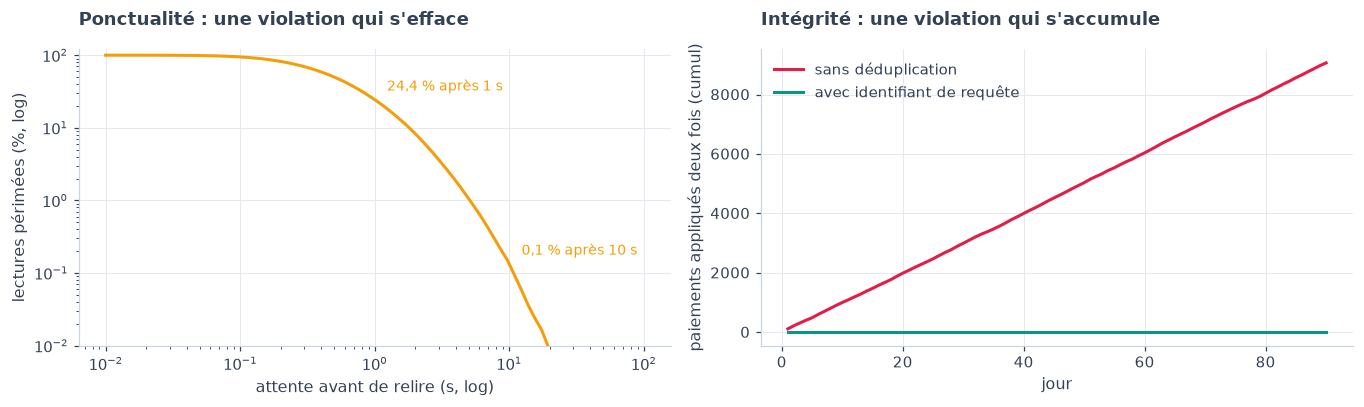

In [2]:
rng = np.random.default_rng(3)
lag = rng.lognormal(np.log(0.5), 1.0, 200_000)                  # délai de traitement (s)
waits = np.logspace(-2, 2, 80)
stale = [(lag > w).mean() for w in waits]
days = np.arange(1, 91)
per_day = 50_000
redeliv = 0.002                                                  # 0,2 % des messages relivrés après une panne
dup_naive = np.cumsum(rng.binomial(per_day, redeliv, days.size))  # appliqués deux fois sans déduplication
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax1.plot(waits, np.array(stale) * 100, color=AMBER)
ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.set_ylim(0.01, 120)
ax1.set_xlabel("attente avant de relire (s, log)"); ax1.set_ylabel("lectures périmées (%, log)")
ax1.set_title("Ponctualité : une violation qui s'efface")
for w in (1, 10):
    v = (lag > w).mean() * 100
    ax1.annotate(f"{v:.1f} % après {w} s".replace(".", ","), (w, v), (8, 6), textcoords="offset points", fontsize=9, color=AMBER)
ax2.plot(days, dup_naive, color=ROSE, label="sans déduplication")
ax2.plot(days, np.zeros_like(days), color=TEAL, label="avec identifiant de requête")
ax2.set_xlabel("jour"); ax2.set_ylabel("paiements appliqués deux fois (cumul)")
ax2.set_title("Intégrité : une violation qui s'accumule"); ax2.legend()
plt.tight_layout(); plt.show()

La probabilité de lire un état périmé chute rapidement avec l'attente : une relecture
une seconde plus tard voit le paiement dans les trois quarts des cas, dix secondes plus
tard dans presque tous. À l'inverse, des relivraisons non dédupliquées s'**accumulent**
indéfiniment : environ cent paiements doublés par jour, soit près de 9 000 au bout de
trois mois, qu'aucune attente ne corrigera.

**Les flux découplent ponctualité et intégrité.** Les transactions ACID offrent les deux
à la fois (linéarisabilité et validation atomique), si bien que la distinction importe
peu tant qu'on raisonne en transactions. Les systèmes de flux d'événements, eux, n'offrent
**aucune** garantie de ponctualité (sauf à attendre explicitement un message), mais
l'**intégrité est au cœur** de leur conception : l'exactement-une-fois sert précisément à
la préserver. Le cours 4 l'a obtenue sans transaction distribuée par quatre mécanismes :

1. représenter le contenu de l'écriture par **un seul message**, facile à écrire
   atomiquement (ce qui s'accorde très bien avec l'event sourcing) ;
2. dériver toutes les autres mises à jour de ce message par des **fonctions déterministes**
   (à la manière de procédures stockées) ;
3. propager un **identifiant de requête** généré par le client à travers toutes les
   étapes, pour dédupliquer de bout en bout ;
4. garder les messages **immuables** et permettre de retraiter les données dérivées, pour
   se remettre des bogues.

> **À retenir.** « Cohérence » recouvre la ponctualité (voir un état à jour : violation
> temporaire) et l'intégrité (absence de corruption : violation permanente). L'intégrité
> est presque toujours la plus importante ; les systèmes de flux la garantissent sans
> transaction distribuée et renoncent à la ponctualité, qu'on peut rétablir en attendant.